# 06 · RabbitMQ 与异步消息（MQ基础篇）


## 本章来源与学习路线

本篇依据百度网盘 `我的资源/day06-MQ入门/PPT/MQ基础篇.pptx`。原 PPT 与在线预览均为 **72 页**，无隐藏页，页码按原文件顺序。整理日期：2026-10-09。

课件预览：[MQ基础篇](https://pan.baidu.com/pfile/docview?path=%2F%E6%88%91%E7%9A%84%E8%B5%84%E6%BA%90%2Fday06-MQ%E5%85%A5%E9%97%A8%2FPPT%2FMQ%E5%9F%BA%E7%A1%80%E7%AF%87.pptx&fsid=651450890299739&size=1252174&view_from=personal_file&md5=c09126bd8l412c41d70ff8e637845d4a&share=0&client=web&scene=main)。

| 阶段 | 课件页码 | 学习目标 |
| --- | --- | --- |
| 初识 MQ | 7—24 | 判断同步与异步边界，理解选型因素 |
| RabbitMQ | 25—33 | 理解交换机、队列、绑定和虚拟主机 |
| Spring AMQP | 34—70 | 收发消息、消费分工、路由、声明与 JSON 转换 |
| 业务改造 | 71—72 | 用支付成功事件通知交易服务更新订单 |

补充读取了 `资料/mq-demo/pom.xml` 的网盘代码预览：父工程为 **Spring Boot 2.7.12**，`maven.compiler.source/target` 为 **8**，包含 publisher、consumer 两个模块，以及 AMQP、Lombok 和测试依赖。资料目录另有 `mq.tar`，本篇未读取其镜像内容，因此不推断 RabbitMQ 的具体版本。

下文区分“课件方案”“整理示例”和“补充/改进”。示例沿用 Boot 2.7.x / Spring AMQP 2.x API，不直接套用新版本的转换器名称。代码用于理解配置与调用关系，已核对课件文本、图示和父 POM，未启动 Broker 或课程服务。


## 1. 同步调用的收益与成本

支付服务依次扣减余额、更新支付状态，再调用交易、通知和积分服务。调用链越长，响应就越慢，新增一个下游也需要修改上游。（课件第 9—10 页）

**同步调用**：调用方等待被调用方的结果，再继续执行。它适合需要立即拿到结果的步骤，例如校验余额是否足够。

```text
支付请求
  → 扣减余额
  → 更新支付状态
  → 更新订单
  → 发短信
  → 加积分
  → 返回结果
```

| 特征 | 业务影响 |
| --- | --- |
| 能立即得到调用结果 | 当前流程可以据此作决定 |
| 上游知道多个下游接口 | 加业务或改接口时需要联动 |
| 串行等待 | 总延迟包含多个调用和本地处理 |
| 共享线程、连接等资源 | 下游慢或故障可能引起级联积压 |

课件以多个 50 ms 步骤说明等待时间累加，并展示约 300 ms 的同步流程。这是教学估算，不是实测指标。并行调用、网络、数据库和队列等待都会改变真实延迟。

不能把全部步骤机械地改成异步。只有当前请求可以不等待的结果，才适合离开同步链路。


## 2. 异步通信与三个角色

发送者可以先完成自身工作，再把事件交给消息代理，由相关服务各自处理。（课件第 12—14 页）

| 角色 | 职责 | 支付例子 |
| --- | --- | --- |
| Publisher / Producer | 创建并发送消息 | 支付服务发布支付成功事件 |
| Broker | 接收、路由、暂存并投递消息 | RabbitMQ |
| Consumer | 接收消息并执行业务 | 交易服务更新订单，通知服务发送通知 |

```text
支付服务完成关键步骤
  → 发送“支付成功”事件到 Broker
  → 返回当前请求

Broker
  ├── 交易服务处理订单
  ├── 通知服务发送通知
  └── 积分服务增加积分
```

**异步通信**的重点是业务发送与业务处理在时间上解耦。发送 API 仍可能发生连接、序列化和网络等待，“异步”不等于发送动作零耗时。

返回支付成功也不意味着短信、积分和订单更新已经全部完成。接口与页面应表达当前确实完成的状态。


## 3. 解耦、故障隔离与削峰填谷

消息缓冲允许消费者按自己的能力处理工作，但缓冲能力和容量都有边界。（课件第 13—14 页）

| 收益 | 如何实现 | 对应代价 |
| --- | --- | --- |
| 扩展业务 | 新服务订阅事件，发送者不逐个调用 | 事件契约仍需管理 |
| 缩短关键响应链 | 移除不必等待的后续处理 | 后续结果稍晚可见 |
| 隔离下游故障 | 消费者停机时消息可以暂存 | 恢复后需补处理积压 |
| 削峰填谷 | 短时峰值进入队列，消费者持续处理 | 增加等待时间与存储占用 |

```text
短时进入：1000 条/秒
持续处理： 600 条/秒
积压增长：约 400 条/秒

流量回落到 200 条/秒后：
消费者仍处理 600 条/秒，可逐步消化历史积压
```

持续进入量大于持续处理能力时，积压会一直增长。队列缓冲不能代替扩容、限流或容量规划。

课件说下游故障不影响上游，理解边界是减少直接调用的故障扩散。Broker 不可用、磁盘不足或发布被阻塞，仍可能影响发送方。异步业务需要关注消息是否到达、是否处理成功以及失败如何恢复。


## 4. MQ 技术选型

MQ 是 Message Queue 的缩写，泛指消息队列产品或消息中间件。应用选型要看场景与验证结果。（课件第 16—24 页）

| 产品 | 课件列出的主要实现语言 | 常见关注场景与能力 |
| --- | --- | --- |
| RabbitMQ | Erlang | 业务消息、灵活交换机路由、AMQP 客户端生态 |
| ActiveMQ | Java | JMS 与既有企业集成，需区分 Classic 和 Artemis |
| RocketMQ | Java | 业务事件与消息处理，按版本核对顺序、延迟等能力 |
| Kafka | Scala / Java | 事件流、日志与批量吞吐，保留和重放能力 |

PPT 的“吞吐高低、延迟微秒/毫秒、可靠性高低”是课程时期的概括。它没有给出版本、消息大小、硬件和确认配置，不能当作当前产品的统一性能排名，也不能据此断言 Kafka 天生不可靠。

| 判断维度 | 需要确认的问题 |
| --- | --- |
| 消息模型 | 竞争消费、广播订阅，还是事件流与重放 |
| 路由能力 | 是否需要按业务键或模式筛选 |
| 可靠性要求 | 哪些阶段要持久化、确认、恢复和幂等 |
| 容量与延迟 | 在自己的负载与配置下是否达标 |
| 运维能力 | 团队是否能处理升级、监控和故障 |
| 客户端生态 | 与语言、框架和现有系统是否适配 |

本章学习 RabbitMQ 的业务消息模型。协议支持也要区分原生功能和插件，不能把课件列出的所有协议理解为默认全开。


## 5. RabbitMQ 的消息路径

消息通常先进入交换机，再按绑定关系进入队列，最后被消费者接收。（课件第 28、31、50 页）

```text
RabbitMQ Broker
  └── Virtual Host：/hmall
      Publisher
        → Exchange
          ├── Binding → Queue A → Consumer A
          └── Binding → Queue B → Consumer B
```

| 名称 | 职责 |
| --- | --- |
| Exchange，交换机 | 根据类型和规则路由消息 |
| Queue，队列 | 保存等待投递或处理的消息 |
| Binding，绑定 | 连接交换机与队列，携带相关路由规则 |
| Routing Key，路由键 | 发布者发送时携带的路由字符串 |
| Binding Key，绑定键 | 队列绑定时设置的匹配条件 |
| Connection / Channel | 连接 Broker，以及连接上的逻辑通信通道 |

普通交换机承担路由职责，消息存储主要由队列负责。消息能否进入队列，取决于交换机类型、绑定和路由键。

向已有交换机发送，没有任何队列匹配时，消息可能被丢弃。发送端没有抛异常，并不能证明消息已进入目标队列；不可路由返回与发送确认在下一章展开。


## 6. Virtual Host 与用户权限

不同项目可以使用相同的队列名，但不应互相读取或修改消息。RabbitMQ 用 Virtual Host 划分逻辑资源空间。（课件第 28、33 页）

| 维度 | 含义 |
| --- | --- |
| Virtual Host | 隔离交换机、队列、绑定等命名空间 |
| User | 登录身份 |
| Permissions | 用户在某个虚拟主机下的配置、写入、读取权限 |
| User Tags | 管理界面角色，与消息资源权限分开 |

课件要求创建 `hmall` 用户和虚拟主机。客户端配置使用 `/hmall`，因此创建时应统一为 **/hmall**。

```text
/hmall：simple.queue → 商城消息
/other：simple.queue → 其他项目消息

同名队列处在不同 Virtual Host 中，属于不同资源
```

添加用户、创建虚拟主机后，还要授予访问该虚拟主机的权限。仅创建用户或赋予管理标签，不能保证应用能声明队列、发送和消费。

Virtual Host 是逻辑隔离，多个虚拟主机仍共享 Broker 的 CPU、内存和磁盘。需要更强的资源或故障隔离时，要考虑独立实例或集群。


## 7. 安装部署与两个端口

PPT 第 27 页引用讲义安装章节，没有给出完整安装命令。资料目录提供 `mq.tar`，以下是部署要点与**补充示例**。

| 端口 | 常见用途 |
| --- | --- |
| 5672 | 客户端 AMQP 通信 |
| 15672 | 开启 management 插件后的 Web 管理界面 |

浏览器能打开 15672，不能证明应用能连接 5672。应用还要使用正确的账户、Virtual Host 和网络地址。

**Docker Compose 整理示例**：镜像变量需要填入已确认的版本和来源；本篇未执行。

```yaml
services:
  rabbitmq:
    image: "${RABBITMQ_IMAGE:?set a verified management image tag}"
    hostname: rabbitmq
    ports:
      - "127.0.0.1:5672:5672"
      - "127.0.0.1:15672:15672"
    environment:
      RABBITMQ_DEFAULT_USER: "${MQ_USERNAME:-hmall}"
      RABBITMQ_DEFAULT_PASS: "${MQ_PASSWORD:?set MQ_PASSWORD}"
      RABBITMQ_DEFAULT_VHOST: /hmall
    volumes:
      - rabbitmq-data:/var/lib/rabbitmq
volumes:
  rabbitmq-data:
```

此示例供同一主机测试。其他机器或容器连接时，需要按网络调整发布地址和访问方式。容器内 `127.0.0.1` 指向当前容器，容器间可使用可解析的服务名。

持久化卷保留 Broker 数据，但它本身不等于消息不丢失。官方镜像的默认用户环境变量主要在首次初始化时生效；已有卷中的账户设置不会因修改变量自动重建。


## 8. 控制台实验：先绑定，再发送

课件要求创建 `hello.queue1`、`hello.queue2`，向 Fanout 交换机发送消息并检查队列。（课件第 30—31 页）

课件写成 `amp.fanout`，RabbitMQ 通常内置的名字是 **amq.fanout**，以实际控制台为准。它也不同于名称为空字符串的**默认交换机**。

| 操作 | 观察目的 |
| --- | --- |
| 创建 hello.queue1 和 hello.queue2 | 先有接收消息的队列 |
| 将两个队列绑定到 amq.fanout | 建立广播路由 |
| 向该交换机发布一条消息 | 观察两个队列各得到一份 |
| 解除一个绑定，再发布 | 验证交换机不会发送给未绑定队列 |

控制台的 Get messages 是主动获取消息，会影响队列状态。检查时应区分获取后重新入队和获取后确认，避免把“消息消失”误判为应用已完成处理。

**默认交换机**的名称是 `""`，类型为 Direct。队列声明时自动与它建立以队列名为路由键的绑定，这解释了后面为什么可以直接“按队列名发送”。


## 9. AMQP、Spring AMQP 与课程工程

AMQP 是 Advanced Message Queuing Protocol，定义消息通信协议。Spring AMQP 在 Java 中提供抽象、模板和监听容器。（课件第 36—39 页）

| 层次 | 作用 |
| --- | --- |
| AMQP | 消息通信协议，需核对具体协议版本 |
| spring-amqp | Spring 的消息、交换机、队列等基础抽象 |
| spring-rabbit | 基于 RabbitMQ 客户端的实现与整合 |
| spring-boot-starter-amqp | Boot 的依赖与自动配置入口 |

官方项目：[Spring AMQP](https://spring.io/projects/spring-amqp)。

课程工程中 publisher 负责发送，consumer 负责监听。已核对其父 POM 使用 Boot 2.7.12、Java 8 编译目标。商城集成时应使用商城父 POM 管理的兼容版本，不能把独立 Demo 的父版本直接覆盖到整个微服务工程。

```xml
<dependency>
    <groupId>org.springframework.boot</groupId>
    <artifactId>spring-boot-starter-amqp</artifactId>
</dependency>
```

把依赖声明在可继承的父工程 `dependencies` 中，模块可继承；仅放在 `dependencyManagement` 中只管理版本，模块仍需声明依赖。


## 10. 客户端连接配置

publisher 和 consumer 都要连接正确的 Broker 与 Virtual Host。（课件第 40 页）

**按课件改写的 application.yml**：用环境属性替代固定主机和演示密码。

```yaml
spring:
  rabbitmq:
    host: "${MQ_HOST:127.0.0.1}"
    port: 5672
    virtual-host: /hmall
    username: "${MQ_USERNAME:hmall}"
    password: "${MQ_PASSWORD}"
```

| 配置不一致 | 常见结果 |
| --- | --- |
| host / port 错误 | 无法建立连接 |
| 用户或密码错误 | 认证失败 |
| Virtual Host 不存在或无权限 | 访问被拒绝 |
| 两端连入不同 Virtual Host | 看到同名队列，却没有同一批消息 |
| 只连接管理端口 | AMQP 协议通信失败 |

Spring Boot 默认通常使用 simple 监听容器，本篇的 `listener.simple` 配置对应它。实际切换到 direct 容器后，应使用对应配置，不能继续假设 simple 的参数会生效。


## 11. 第一条消息：发送与监听

先在 `/hmall` 中创建 `simple.queue`，再配置两个应用。发送端使用 RabbitTemplate，接收端注册监听方法。（课件第 38、41—43 页）

**publisher 整理示例**：

```java
@Service
@RequiredArgsConstructor
public class SimplePublisher {
    private final RabbitTemplate rabbitTemplate;

    public void send() {
        rabbitTemplate.convertAndSend(
            "simple.queue",
            "hello, spring amqp!"
        );
    }
}
```

**consumer 整理示例**：

```java
@Component
@Slf4j
public class SimpleListener {
    @RabbitListener(queues = "simple.queue")
    public void receive(String message) {
        log.info("收到消息：{}", message);
    }
}
```

| API | 理解 |
| --- | --- |
| RabbitTemplate | 发送消息的模板工具 |
| convertAndSend(queueName, payload) | 使用默认交换机，以队列名作为路由键 |
| @RabbitListener(queues = "...") | 创建监听该队列的消息消费者 |

「按队列名发送」要求队列已存在，默认交换机不会替应用创建任意队列。`queues` 形式的监听注解也不等于自动声明该队列；自动声明的方式见第 19—20 节。


## 12. Work Queue：多个消费者分担任务

一个消费者处理不过来时，可以让多个消费者监听同一个队列。（课件第 45—48 页）

```text
Publisher → work.queue
                ├── Consumer 1
                └── Consumer 2

一条投递由其中一个消费者接收，两个消费者共同分担工作
```

课件实验向 `work.queue` 发送 50 条消息，两个监听者分别模拟每秒处理 40 条、5 条：

```java
// publisher 中发送；work.queue 已预先声明
for (int i = 1; i <= 50; i++) {
    rabbitTemplate.convertAndSend("work.queue", "task-" + i);
}
```

```java
@Component
@Slf4j
public class WorkListeners {
    @RabbitListener(queues = "work.queue")
    public void fast(String message) throws InterruptedException {
        Thread.sleep(25);
        log.info("fast 完成：{}", message);
    }

    @RabbitListener(queues = "work.queue")
    public void slow(String message) throws InterruptedException {
        Thread.sleep(200);
        log.info("slow 完成：{}", message);
    }
}
```

Sleep 用来制造速度差，实际处理能力还受日志、网络与线程调度影响。启动更多应用实例或增加容器并发，也能增加该队列的消费者数量。

> Work Queue 提供竞争消费。一条消息可能在失败后被重新投递，因此“每次只交给一个消费者”不等于业务必然只执行一次。


## 13. prefetch 与未确认消息

如果 Broker 提前向慢消费者发了很多消息，即使快消费者有空，也不能直接接走这些已经投递但未确认的工作。（课件第 47—48 页）

**prefetch** 控制消费者可持有的未确认投递数量。在正常 Spring AUTO 或 MANUAL 确认流程下，设为 1 可以让消费进度更多地影响后续分配。

```yaml
spring:
  rabbitmq:
    listener:
      simple:
        prefetch: 1
        acknowledge-mode: auto
```

这里的 AUTO 是 **Spring 容器根据监听方法是否成功完成来确认**，不是 RabbitMQ 客户端的 `autoAck=true`。后者交付后就视为确认，不能用来建立“处理完再发下一条”的约束。

```text
prefetch = 1
  快消费者：处理完成 → 确认 → 再获得消息
  慢消费者：尚未完成 → 未确认额度已满
```

| 参数 / 状态 | 含义 |
| --- | --- |
| prefetch | 未确认投递的额度，通常按消费者控制 |
| consumer concurrency | 监听容器同时运行多少消费者 |
| messages_ready | 在队列中等待投递的消息 |
| messages_unacknowledged | 已投递、尚未确认的消息 |

prefetch=1 不会把整个队列变成单线程，也不保证多消费者的完成顺序。低值有利于任务耗时不均时的分配，高值可能提高短任务的吞吐，应结合处理耗时和内存验证。

消费者完成前把任务转交到普通异步线程、监听方法立即返回，也可能过早确认。确认时点需要与业务真正完成的时点一致。


## 14. 发布订阅：业务各有一个队列

短信和订单更新都要处理支付成功事件时，不能把它们放在同一队列竞争消费。（课件第 50—52、72 页）

```text
同一业务扩容：
  订单队列 → 订单实例 A / 订单实例 B，分担工作

不同业务订阅：
  支付事件交换机
    ├── 订单队列 → 订单服务
    └── 通知队列 → 通知服务
```

| 需求 | 拓扑 |
| --- | --- |
| 同一业务多个实例分担任务 | 多个消费者监听一个队列 |
| 多个业务都收到事件 | 交换机绑定多个业务队列 |
| 某业务既订阅事件又扩容 | 该业务一个队列，多个消费实例 |

发布订阅中的复制发生在**队列层面**。一个队列绑定交换机后，不会因它有多个消费者就给每个消费者都复制一份。

队列应按业务责任划分，订单、通知和积分各自消费，才能分别积压、恢复和扩容。


## 15. Fanout：广播到所有绑定队列

所有订阅者都需要消息时，可以使用 Fanout 交换机。（课件第 51—53 页）

| 资源 | 课件统一名称 |
| --- | --- |
| 交换机 | hmall.fanout |
| 队列 | fanout.queue1、fanout.queue2 |
| 绑定 | 两个队列分别绑定交换机 |
| 路由键 | Fanout 不按它筛选队列 |

```java
rabbitTemplate.convertAndSend(
    "hmall.fanout", "", "hello, everyone!"
);
```

```text
hmall.fanout
  ├── fanout.queue1 → Listener 1
  └── fanout.queue2 → Listener 2
```

监听方法分别使用 `@RabbitListener(queues = "fanout.queue1")` 和 `fanout.queue2`。每个绑定队列接收一份，随后按自己的消费者数量分发。

课件第 53 页发送示例写 `itcast.fanout`，与前页声明的 `hmall.fanout` 不一致。本篇统一为 hmall.fanout，避免向另一个名称发送。


## 16. Direct：路由键精确匹配

不同类别消息只交给相应业务，可以用 Direct 交换机按字符串精确匹配。（课件第 55—57 页）

| 队列 | Binding Key |
| --- | --- |
| direct.queue1 | blue、red |
| direct.queue2 | yellow、red |

```java
rabbitTemplate.convertAndSend("hmall.direct", "blue", "蓝色消息");
rabbitTemplate.convertAndSend("hmall.direct", "red", "红色消息");
```

| Routing Key | 到达队列 |
| --- | --- |
| blue | direct.queue1 |
| yellow | direct.queue2 |
| red | 两个队列各一份 |
| green | 没有匹配的绑定 |

同一队列可以有多个绑定键，同一绑定键也可以对应多个队列。Direct 并不意味着只能发给一个队列。

“与 Fanout 类似”只表示某个键可能匹配多个队列。Direct 仍依赖精确匹配，不会对其他键自动广播。


## 17. Topic：按单词模式匹配

路由键需要同时描述地区、事件类型等维度时，可以使用 Topic 交换机。（课件第 59—61 页）

路由键通常用点号分隔单词，例如 `china.news`、`china.weather`。**绑定键**中可以使用通配符：

| 符号 | 匹配范围 |
| --- | --- |
| * | 恰好一个单词 |
| # | 零个或多个单词 |

课件声明 `hmall.topic`，给 `topic.queue1` 绑定 `china.#`，给 `topic.queue2` 绑定 `#.news`。

```java
rabbitTemplate.convertAndSend("hmall.topic", "china.news", "中国新闻");
rabbitTemplate.convertAndSend("hmall.topic", "japan.news", "日本新闻");
rabbitTemplate.convertAndSend("hmall.topic", "china.weather", "中国天气");
```

| Routing Key | china.# | #.news | china.* |
| --- | --- | --- | --- |
| china.news | 匹配 | 匹配 | 匹配 |
| china.weather | 匹配 | 不匹配 | 匹配 |
| japan.news | 不匹配 | 匹配 | 不匹配 |
| china.city.news | 匹配 | 匹配 | 不匹配 |
| china | 匹配 | 不匹配 | 不匹配 |

`#` 可以匹配零个词，因此 `china.#` 也可以匹配 `china`。`*` 匹配的是一个词，不能当作任意长度字符串通配符。

第 60 页标题误写了“DirectExchange”，该页使用 `hmall.topic` 与通配符，实际是 Topic 实验。


## 18. 三种交换机与默认交换机的选择

选交换机前先明确接收范围，再选择匹配规则。

| 交换机 | 匹配方式 | 常见场景 |
| --- | --- | --- |
| 默认交换机 `""` | 队列名作为精确路由键，自动绑定 | 简单点对队列发送 |
| Fanout | 所有绑定队列 | 同一种事件广播给多个业务 |
| Direct | Binding Key 与 Routing Key 精确相同 | 按固定类别定向通知 |
| Topic | 按点号单词与 * / # 模式匹配 | 按业务、地区、事件类型组合订阅 |

同一条消息通过多个匹配绑定路由到**同一个队列**时，RabbitMQ 不因这些重复匹配而在该次路由中给该队列放多份；不同队列则各接收一份。

消费失败重投递或发送方重复发布，仍可能使同一业务事件多次执行，不能把路由去重当作业务幂等。

交换机类型是拓扑的一部分。已存在同名 Direct 交换机后，不能直接把它重新声明为 Topic；需要迁移或换名称。


## 19. 用 Bean 声明队列、交换机与绑定

手工点控制台容易漏绑定，也难以保证各环境一致。Spring AMQP 可以把拓扑声明写进配置。（课件第 63—64、66 页）

| 类 / 构建器 | 声明对象 |
| --- | --- |
| Queue / QueueBuilder | 队列 |
| FanoutExchange、DirectExchange、TopicExchange / ExchangeBuilder | 交换机 |
| Binding / BindingBuilder | 绑定关系 |

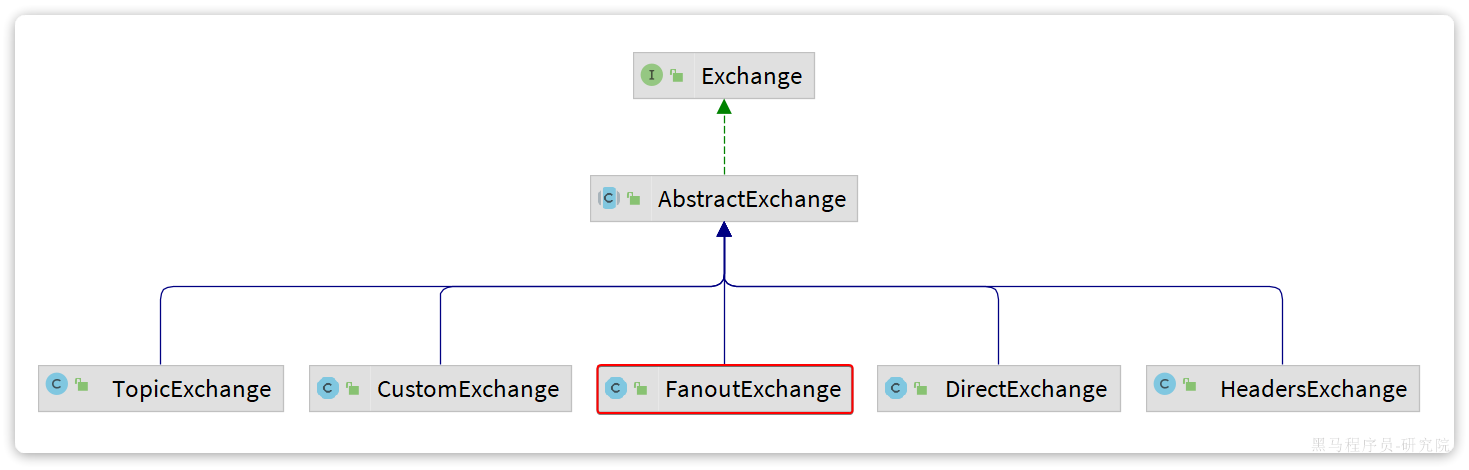

**Fanout 整理示例**，放在需要声明拓扑的 consumer 应用：

```java
@Configuration
public class FanoutConfig {
    @Bean
    public FanoutExchange fanoutExchange() {
        return ExchangeBuilder.fanoutExchange("hmall.fanout")
            .durable(true).build();
    }

    @Bean
    public Queue fanoutQueue1() {
        return QueueBuilder.durable("fanout.queue1").build();
    }

    @Bean
    public Queue fanoutQueue2() {
        return QueueBuilder.durable("fanout.queue2").build();
    }

    @Bean
    public Binding fanoutBinding1(
            @Qualifier("fanoutQueue1") Queue queue,
            FanoutExchange fanoutExchange) {
        return BindingBuilder.bind(queue).to(fanoutExchange);
    }

    @Bean
    public Binding fanoutBinding2(
            @Qualifier("fanoutQueue2") Queue queue,
            FanoutExchange fanoutExchange) {
        return BindingBuilder.bind(queue).to(fanoutExchange);
    }
}
```

这里的 Queue 是 `org.springframework.amqp.core.Queue`，不是 `java.util.Queue`。多个同类型 Bean 用 Qualifier 明确注入，避免选错队列。

自动声明需要 RabbitAdmin / Boot 自动配置正常启用、连接成功，并且用户有配置权限。它不会随意修改已有对象的类型、durable 或其他冲突参数；参数不一致可能导致声明失败和 `PRECONDITION_FAILED`。

durable 声明保留队列或交换机定义。消息本身的持久化、发送确认与消费确认属于其他环节，不能仅凭这个参数判断完整可靠性。


## 20. 用监听注解声明拓扑

简单消费者可以在监听方法旁同时声明队列、交换机和绑定。（课件第 65—66 页）

**Direct 整理示例**：

```java
@Component
@Slf4j
public class DirectListeners {
    @RabbitListener(bindings = @QueueBinding(
        value = @Queue(name = "direct.queue1", durable = "true"),
        exchange = @Exchange(
            name = "hmall.direct",
            type = ExchangeTypes.DIRECT,
            durable = "true"
        ),
        key = {"red", "blue"}
    ))
    public void receive1(String message) {
        log.info("queue1 收到：{}", message);
    }

    @RabbitListener(bindings = @QueueBinding(
        value = @Queue(name = "direct.queue2", durable = "true"),
        exchange = @Exchange(
            name = "hmall.direct",
            type = ExchangeTypes.DIRECT,
            durable = "true"
        ),
        key = {"red", "yellow"}
    ))
    public void receive2(String message) {
        log.info("queue2 收到：{}", message);
    }
}
```

| 注解 | 职责 |
| --- | --- |
| @RabbitListener | 注册监听端点 |
| @QueueBinding | 声明完整绑定关系 |
| @Queue | 声明队列 |
| @Exchange | 声明交换机 |

这里 `@Queue` 是 `org.springframework.amqp.rabbit.annotation.Queue`，与上一节的 core.Queue 同名但属于不同类型。`@Exchange`、`@QueueBinding`、`@RabbitListener` 也来自 rabbit.annotation 包，ExchangeTypes 来自 `org.springframework.amqp.core`。

Topic 注解方案可以把类型改为 `ExchangeTypes.TOPIC`，再用 `key = "china.#"` 等绑定键。Fanout 的 key 不参与路由筛选。

Bean 方案便于集中管理共享拓扑，注解方案便于把简单消费与绑定放在一起。不要用两套方案声明同名却参数不同的资源。


## 21. 消息转换：Java 对象与字节

消息跨网络传输的是字节，监听方法却经常接收 String、Map 或 DTO。MessageConverter 负责转换。（课件第 68—69 页）

```text
发送端：
  Java 对象 → MessageConverter → body 字节 + 消息属性
  → RabbitMQ

接收端：
  body 字节 + 消息属性 → MessageConverter → Java 对象
  → 监听方法
```

课件用 Map 测试对象发送，并指出默认 SimpleMessageConverter 的 JDK 序列化问题。更准确地说：

| 默认转换器接收到的内容 | 常见处理 |
| --- | --- |
| String | 转为文本字节 |
| byte[] | 直接使用字节 |
| 可序列化对象 | 使用 Java 原生序列化 |

不是所有消息都走 ObjectOutputStream。HashMap 等 Serializable 对象使用 Java 序列化时，可读性和跨语言兼容性较差，反序列化还需要处理类型信任等安全问题。

消息转换只解决数据表示，不负责路由、业务校验或事务一致性。


## 22. 两端配置 JSON 转换器

JSON 有利于阅读、跨语言和契约管理。发送端与接收端应采用兼容的转换器与字段定义。（课件第 70 页）

课件给出的 Jackson 依赖由兼容父 POM 管理版本；starter 已经带入时不必重复添加：

```xml
<dependency>
    <groupId>com.fasterxml.jackson.core</groupId>
    <artifactId>jackson-databind</artifactId>
</dependency>
```

**两端都配置**课程时期的 MessageConverter：

```java
@Configuration
public class MessageConfig {
    @Bean
    public MessageConverter messageConverter() {
        return new Jackson2JsonMessageConverter();
    }
}
```

两个类型来自 `org.springframework.amqp.support.converter`。Boot 默认模板和监听容器工厂正常使用该 Bean 时，收发两侧会按 JSON 转换；自行创建模板或容器工厂的工程需要显式核对。

```java
// object.queue 已声明；示例适配 Java 8
Map<String, Object> payload = new HashMap<>();
payload.put("name", "Jack");
payload.put("age", 21);
rabbitTemplate.convertAndSend("object.queue", payload);
```

```json
{"name":"Jack","age":21}
```

```java
@RabbitListener(queues = "object.queue")
public void receiveObject(Map<String, Object> payload) {
    log.info("收到对象：{}", payload);
}
```

JSON 使用 `application/json` 等消息属性表达内容类型，常见转换器还可能携带类型信息。不同服务不应只靠生产者的 Java 类全名约定契约；应核对目标 DTO、字段类型和类型信任范围，避免简单地对外部类型全部开放反序列化。

修改转换器不会把队列里的历史 Java 序列化消息自动转成 JSON。迁移时应区分旧消息与新消息，确认兼容处理或使用新的队列。


## 23. 支付成功事件的消息契约

PPT 第 72 页提出支付异步改造，但没有规定完整 DTO。下面是**整理示例**，用明确的事件字段描述一次支付完成。

```json
{
  "eventId": "pay-success-9001",
  "eventType": "PAY_SUCCESS",
  "schemaVersion": 1,
  "payOrderId": 9001,
  "orderId": 1001,
  "paidAt": "2026-10-09T10:00:00Z"
}
```

| 字段 | 用途 |
| --- | --- |
| eventId | 同一次业务事件的稳定标识，供去重与排查 |
| eventType / schemaVersion | 识别语义与契约版本 |
| payOrderId | 支付单标识 |
| orderId | 目标商城订单标识 |
| paidAt | 有明确时区的业务发生时间 |

同一事件重试发布时，应保留 eventId。只给每次发送生成全新 ID，会让消费者难以识别重复事件。

Java 8 整理 DTO，可放在约定的共享契约模块中：

```java
@Data
@NoArgsConstructor
@AllArgsConstructor
public class PaySuccessEvent {
    private String eventId;
    private String eventType;
    private Integer schemaVersion;
    private Long payOrderId;
    private Long orderId;
    private String paidAt;
}
```

采用 String 时间字段是为了让这个入门示例少依赖时间序列化配置，实际工程可选统一的时间类型和 ObjectMapper 设置。

新增可选字段通常比删除字段或改变字段类型更容易兼容。事件应表达已发生的事实，消费者需要哪些用户或金额信息，应按真实业务契约补充。


## 24. 余额支付的异步拓扑

课件将支付服务对交易服务的 OpenFeign 通知改为 MQ。扣减余额和支付状态更新仍是当前关键流程，消息负责通知后续业务。（课件第 72 页）

```text
支付服务
  → pay.topic（Topic）
      ├── pay.success → mark.order.pay.queue → 交易服务
      └── pay.#       → pay.notify.queue     → 通知服务
```

| 资源 | 作用 |
| --- | --- |
| pay.topic | 支付相关事件交换机 |
| Routing Key：pay.success | 支付成功事件 |
| mark.order.pay.queue | 交易服务更新订单的队列 |
| Binding Key：pay.success | 交易服务只接收成功事件 |
| pay.notify.queue / pay.# | 通知服务接收支付领域匹配事件 |

通知服务订阅 `pay.#` 的范围更宽，未来存在 `pay.failed` 等消息时，应识别事件语义或缩小订阅范围。不同事件共用队列时，不能假设所有消息都能直接转换成同一个成功 DTO。

将清单中的队列、交换机和绑定声明在部署配置或相应消费应用中，发送端再使用同一名称。MQ 只替换了后续通知方式，不会自动协调远程余额扣减与支付库的原子性。


## 25. 发送支付成功消息的时点

订单只有在支付确实成功后才能变为已支付，因此消息发布时间必须与本地状态对应。

**整理示例**：下面的方法接收已经提交的支付事实，仅演示消息发送，不是完整支付事务：

```java
@Service
@RequiredArgsConstructor
public class PayEventPublisher {
    private final RabbitTemplate rabbitTemplate;

    public void publish(PaySuccessEvent committedEvent) {
        rabbitTemplate.convertAndSend(
            "pay.topic",
            "pay.success",
            committedEvent
        );
    }
}
```

| 发送顺序 | 可能的故障窗口 |
| --- | --- |
| 先发消息，再提交支付库 | 消费者先更新订单，支付库随后回滚 |
| 先提交支付库，再发消息 | 提交后应用宕机或发送失败，通知没有发出 |
| 数据库事务中直接 convertAndSend | 普通调用不会让数据库与 Broker 自动原子提交 |

课件的入门目标是跑通异步通知，不等于解决上述故障窗口。补充方案可在同一本地事务中保存支付结果与待发送事件，再由发布任务可靠发送、重试和更新状态，这常称为 **Transactional Outbox，事务发件箱**。

在提交后回调发送能避免本地回滚前过早通知，但提交后宕机的窗口仍存在。发送确认也只证明某个消息阶段的结果，不能直接证明订单已更新。


## 26. 交易服务消费与幂等更新

交易服务收到支付成功事件后，需要校验字段，并把对应订单从未支付变为已支付。重复事件不能产生重复副作用。

**监听整理示例**：

```java
@Component
@RequiredArgsConstructor
public class PaySuccessListener {
    private final OrderPaymentService orderPaymentService;

    @RabbitListener(bindings = @QueueBinding(
        value = @Queue(name = "mark.order.pay.queue", durable = "true"),
        exchange = @Exchange(
            name = "pay.topic",
            type = ExchangeTypes.TOPIC,
            durable = "true"
        ),
        key = "pay.success"
    ))
    public void onPaySuccess(PaySuccessEvent event) {
        if (event == null
                || event.getEventId() == null
                || event.getOrderId() == null
                || !"PAY_SUCCESS".equals(event.getEventType())
                || !Integer.valueOf(1).equals(event.getSchemaVersion())) {
            throw new IllegalArgumentException("支付事件不符合当前契约");
        }
        orderPaymentService.markPaid(event);
    }
}
```

OrderPaymentService 是待业务工程实现的契约，不是已验证的课程源码。它应在本地事务内校验支付事实与订单，并按状态机执行更新；生产中还需检查空字符串、支付单关联等约束。

**补充：条件更新思路**，字段与状态值应按实际数据库替换：

```sql
UPDATE orders
SET status = :paid_status, pay_time = :paid_at
WHERE id = :order_id AND status = :unpaid_status;
```

这里的 `:参数` 是绑定参数占位符，不是可直接执行的建表或查询脚本。

| 更新结果 | 后续判断 |
| --- | --- |
| 更新 1 行 | 本次完成未支付到已支付转换 |
| 更新 0 行且已支付、支付事实一致 | 可视为重复事件，避免重复副作用 |
| 更新 0 行且订单不存在、已取消等 | 按业务状态处理，不能全部当成成功 |

通知、积分等后续操作有各自的幂等需求，不能只靠订单 UPDATE 去重。更通用的办法是在消费端用唯一 eventId 保存处理记录，并与业务修改放入同一本地事务。

监听业务失败时应保留失败结果。捕获异常后只打日志并正常返回，可能让容器确认消息；处理失败的重试与退出策略在 MQ 高级篇继续展开。


## 27. 入门模型与消息可靠性的边界

MQ 的完整结果包含多个阶段。一个阶段成功，不能推导出后续全部成功。

```text
支付库提交
  → 发送端发布
  → Broker 接收
  → 交换机路由到队列
  → 消费者收到
  → 订单库提交
  → 消费确认
```

| 判断 | 实际能说明什么 |
| --- | --- |
| convertAndSend 正常返回 | 不能据此断言业务消费者已处理 |
| 消息在队列中可见 | 当前已进入该队列，业务可能仍未执行 |
| 消费者打印日志 | 需要确认日志位置，不能代替数据库提交 |
| 队列 ready 数量为 0 | 可能仍有 unacknowledged 消息 |
| 本地订单更新成功 | 还需考虑确认失败后的重新投递 |

**消息确认**回答某一阶段是否完成，**幂等**保证重复执行不会多产生业务效果，**补偿 / 重试**处理暂时失败，三者解决不同问题。

课程后续高级篇列有发送者重连、发送确认、持久化、Lazy Queue、消费确认、失败重试、业务幂等和延迟消息。本篇保留这些边界，不把入门示例当成完整可靠消息方案。


## 28. 实验验证与故障定位

按模型逐个验证，比一次引入全部业务更容易定位问题。以下是验证设计，本次没有启动 RabbitMQ 或运行 Demo。

| 实验 | 预期与检查点 |
| --- | --- |
| simple.queue | 同一虚拟主机下，字符串进入并被监听 |
| Work Queue 50 条任务 | 两个消费者合计处理任务，比较 prefetch 变化 |
| Fanout | 两个不同队列各收到一份 |
| Direct blue / yellow / red | 分别路由到队列 1、队列 2、两个队列 |
| Topic | 验证 china.news、japan.news 与 china.city.news |
| JSON 对象 | body 可阅读，两端字段类型一致 |
| 支付成功事件 | 订单按规则变为已支付，通知独立消费 |
| 重复支付事件 | 订单状态和附加副作用不重复变化 |

| 现象 | 优先排查 |
| --- | --- |
| 连接被拒绝 | 主机、5672、容器网络与 Broker 是否运行 |
| ACCESS_REFUSED | 用户、密码、Virtual Host 与权限 |
| 发了却没有消息 | 交换机名、绑定、路由键与 Virtual Host |
| simple.queue 监听失败 | 队列是否已声明，自动声明是否正常 |
| 慢消费者占了许多消息 | prefetch、确认方式与容器配置类型 |
| 订单与通知只有一方收到 | 是否错误地共用一个竞争消费队列 |
| PRECONDITION_FAILED | 同名队列 / 交换机的类型或参数冲突 |
| JSON 转换异常 | 转换器、content type、字段类型、旧消息格式 |
| 队列无积压但订单未更新 | 未确认量、异常是否被吞、状态更新条件 |

消息排查至少记录 eventId、业务订单号、交换机、路由键、队列和处理状态。应用日志、Broker 指标与业务数据库共同提供证据，单看其中一处可能误判。


## 29. 核心回顾与面试提示

| 知识点 | 应能判断的结论 |
| --- | --- |
| 同步与异步 | 当前结果是否必须等待，后续结果如何表达 |
| MQ 削峰 | 缓冲峰值，但持续处理能力必须跟得上 |
| Exchange / Queue | 交换机路由，队列存储并交给消费者 |
| Virtual Host | 资源命名空间隔离，仍共享 Broker 资源 |
| 默认交换机 | 空名称，以队列名自动精确路由 |
| Work Queue | 同业务竞争消费，仍可能失败重投递 |
| prefetch | 限制未确认投递数量，不是总消费者数量 |
| Fanout / Direct / Topic | 广播、精确键匹配、单词模式匹配 |
| 拓扑声明 | Bean 或注解，已有资源参数必须兼容 |
| MessageConverter | 对象与字节转换，JSON 也需要契约 |
| 支付事件 | 各业务有自己的队列，成功事实与发布时点一致 |
| 可靠性 | 发送、路由、消费、提交与确认是不同阶段 |

**面试提示**：先用余额支付说明为什么把通知、积分等步骤异步化，再画出“交换机 → 多业务队列 → 各队列的多个实例”。解释 Work Queue 与广播的区别，说明 prefetch=1 限制的是未确认投递，Direct 为什么也能路由到多个队列，以及 Topic 的 * / # 分别匹配多少个词。最后指出消息发送成功不代表订单已更新，数据库提交与消息发布存在故障窗口，重复投递需要业务幂等。
